In [2]:
# Setup
import inspect, os, re, time, joblib, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import sklearn
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

import nlp_utils
from nlp_utils import (clean_text, tokenize, heuristic_score, heuristic_sentiment, vader_sentiment,
                       POSITIVE_WORDS, NEGATIVE_WORDS, NEGATIONS, STOP_WORDS)

warnings.filterwarnings('ignore')
np.random.seed(42)
sns.set_theme(style='whitegrid')
os.makedirs('screenshots', exist_ok=True)

# Task 1: NLP Fundamentals, Pipeline & Data Exploration


In [3]:
# 1.4 Load and inspect
df = pd.read_csv('dataset/Tweets.csv')
cols = ['text', 'airline_sentiment', 'airline']
print('shape:', df.shape)
print(df[cols].head())
print(df[cols].isnull().sum())
print('duplicate tweets:', df.duplicated(subset='text').sum())

df = df[cols].drop_duplicates(subset='text').reset_index(drop=True)
print('shape after dropping duplicates:', df.shape)
for tweet in df['text'].head(5):
    print(tweet)

shape: (14640, 15)
                                                text airline_sentiment  \
0                @VirginAmerica What @dhepburn said.           neutral   
1  @VirginAmerica plus you've added commercials t...          positive   
2  @VirginAmerica I didn't today... Must mean I n...           neutral   
3  @VirginAmerica it's really aggressive to blast...          negative   
4  @VirginAmerica and it's a really big bad thing...          negative   

          airline  
0  Virgin America  
1  Virgin America  
2  Virgin America  
3  Virgin America  
4  Virgin America  
text                 0
airline_sentiment    0
airline              0
dtype: int64
duplicate tweets: 213
shape after dropping duplicates: (14427, 3)
@VirginAmerica What @dhepburn said.
@VirginAmerica plus you've added commercials to the experience... tacky.
@VirginAmerica I didn't today... Must mean I need to take another trip!
@VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests

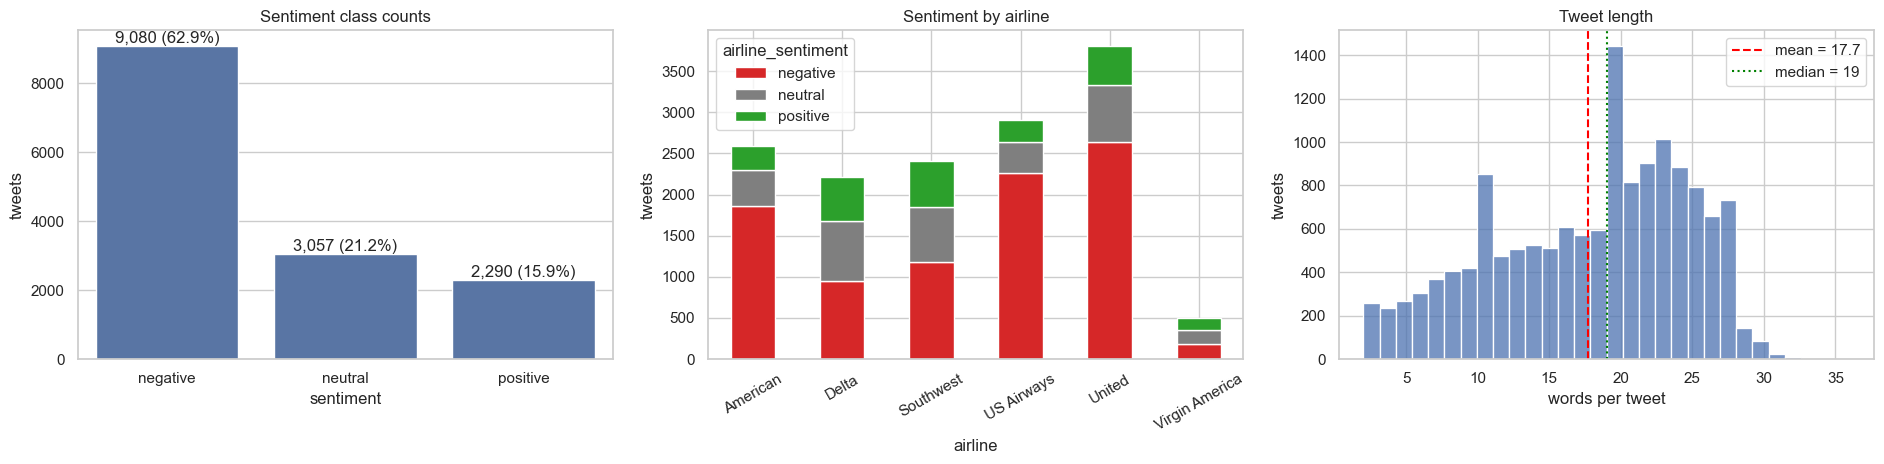

In [4]:
# 1.5 EDA plots
order = ['negative', 'neutral', 'positive']
counts = df['airline_sentiment'].value_counts()[order]
df['n_words'] = df['text'].str.split().str.len()

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
sns.barplot(x=counts.index, y=counts.values, order=order, ax=ax[0])
ax[0].bar_label(ax[0].containers[0], labels=[f'{v:,} ({v / len(df):.1%})' for v in counts.values])
ax[0].set(title='Sentiment class counts', xlabel='sentiment', ylabel='tweets')

pd.crosstab(df['airline'], df['airline_sentiment'])[order].plot(kind='bar', stacked=True, ax=ax[1], color=['tab:red', 'tab:gray', 'tab:green'])
ax[1].set(title='Sentiment by airline', xlabel='airline', ylabel='tweets')
ax[1].tick_params(axis='x', rotation=30)

sns.histplot(df['n_words'], bins=30, ax=ax[2])
ax[2].axvline(df['n_words'].mean(), color='red', linestyle='--', label=f"mean = {df['n_words'].mean():.1f}")
ax[2].axvline(df['n_words'].median(), color='green', linestyle=':', label=f"median = {df['n_words'].median():.0f}")
ax[2].set(title='Tweet length', xlabel='words per tweet', ylabel='tweets')
ax[2].legend()
plt.tight_layout()
plt.savefig('screenshots/eda_plots.png', dpi=150)
plt.show()

In [5]:
# 1.6 Challenges in NLP: evidence from real tweets
def pick(mask):
    return df[mask].sample(1, random_state=42)['text'].iloc[0]

neg = df['airline_sentiment'] == 'negative'
challenges = pd.DataFrame([
    ('Negation', pick(df['text'].str.contains(r"\bnot (?:happy|good|great|worth)", case=False)),
     'The positive word "happy/good" is flipped by "not"; a plain word count sees only the positive word.'),
    ('Sarcasm / irony', pick(neg & df['text'].str.contains(r'thanks for nothing|great job|love how|yeah right|oh great|nice job', case=False)),
     'Positive words are used to complain; the real meaning needs tone and world knowledge.'),
    ('Slang / misspelling', pick(df['text'].str.contains(r'\b(?:u|ur|thx|omg|wtf|smh|cuz)\b', case=False)),
     'Short forms and typos are not in a dictionary or lexicon, so they carry no known meaning.'),
    ('Emoji / special symbols', pick(df['text'].str.contains(r'[^\x00-\x7F]')),
     'Emojis can carry the whole sentiment, but plain letter-only cleaning throws them away.'),
    ('Hard to label even for a person', pick((df['airline_sentiment'] == 'positive') & df['text'].str.contains(r'delay|cancel|lost|wait', case=False)),
     'Praise and a problem are mixed in one tweet, so even humans could disagree on the label.'),
], columns=['challenge', 'real tweet from the data', 'why it is hard for a computer'])
pd.set_option('display.max_colwidth', 160)
challenges

,challenge,real tweet from the data,why it is hard for a computer
0,Negation,"@SouthwestAir well, it was fun while it lasted. Not happy about the change to redeeming reward points. Won't be loyal anymore.","The positive word ""happy/good"" is flipped by ""not""; a plain word count sees only the positive word."
1,Sarcasm / irony,"@USAirways thanks for nothing. Bought two tix through you to Disney and my friend can't go and now I have to eat the 400, plus 600 for new 1",Positive words are used to complain; the real meaning needs tone and world knowledge.
2,Slang / misspelling,@JetBlue Now ur asking for the heavy guns! You know #IWouldDoAnythingForLove https://t.co/Yx1DQJn8nL #BrandMance #LoveSongFriday,"Short forms and typos are not in a dictionary or lexicon, so they carry no known meaning."
3,Emoji / special symbols,@USAirways yes I know the industry procedure on baggage. Thanks for helping..... 😉 what about the impossible connection that started this?,"Emojis can carry the whole sentiment, but plain letter-only cleaning throws them away."
4,Hard to label even for a person,"I appreciate the reply. RT @SouthwestAir: @luxclark We’re so sorry to keep you waiting, Laura. An Agent will be with you shortly...^CB","Praise and a problem are mixed in one tweet, so even humans could disagree on the label."


# Task 2: Text Cleaning with RegEx & Tokenisation


In [6]:
# 2.2 RegEx practice cells
sample = "@united thanks for the 3 hour delay!!! #worstflight http://t.co/abc123   never again"
print('URLs        :', re.findall(r'https?://\S+', sample))
print('@mentions   :', re.findall(r'@\w+', sample))
print('hashtags    :', re.sub(r'#(\w+)', r'\1', sample))
print('numbers     :', re.findall(r'\d+', sample))
print('punctuation :', re.sub(r'[^a-z\s]', '', sample.lower()))
print('whitespace  :', re.sub(r'\s+', ' ', sample))

URLs        : ['http://t.co/abc123']
@mentions   : ['@united']
hashtags    : @united thanks for the 3 hour delay!!! worstflight http://t.co/abc123   never again
numbers     : ['3', '123']
punctuation : united thanks for the  hour delay worstflight httptcoabc   never again
whitespace  : @united thanks for the 3 hour delay!!! #worstflight http://t.co/abc123 never again


| Pattern | Meaning of each symbol | Example match |
|---|---|---|
| `https?://\S+` | `http`, optional `s` (`?`), `://`, then one or more (`+`) non-space characters (`\S`) | `http://t.co/abc123` |
| `@\w+` | `@` followed by one or more word characters (`\w`) | `@united` |
| `#(\w+)` | `#` followed by a captured word; the replacement `\1` keeps only the captured word | `#worstflight` -> `worstflight` |
| `\d+` | one or more digits | `3` |
| `[^a-z\s]` | anything that is NOT a letter (`a-z`) or whitespace (`\s`) | `!`, `3`, `:` |
| `\s+` | one or more whitespace characters | three spaces -> one space |

In [7]:
# 2.3 clean_text() function (it lives in nlp_utils.py so that the app uses the same code)
print(inspect.getsource(clean_text))

df['clean_text'] = df['text'].apply(clean_text)
for i in range(5):
    print('raw    :', df['text'].iloc[i])
    print('cleaned:', df['clean_text'].iloc[i])
    print()

empty = df['clean_text'] == ''
print('tweets that became empty after cleaning:', empty.sum())
df = df[~empty].reset_index(drop=True)      # they hold no words, so they are dropped
print('tweets kept:', len(df))

def clean_text(text):
    """lowercase -> remove URLs and @mentions -> keep hashtag word -> expand n't -> keep letters only -> collapse spaces"""
    text = text.lower().replace('’', "'")
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    text = re.sub(r"won't", 'will not', text)
    text = re.sub(r"can't", 'can not', text)
    text = re.sub(r"n't\b", ' not', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

raw    : @VirginAmerica What @dhepburn said.
cleaned: what said

raw    : @VirginAmerica plus you've added commercials to the experience... tacky.
cleaned: plus you ve added commercials to the experience tacky

raw    : @VirginAmerica I didn't today... Must mean I need to take another trip!
cleaned: i did not today must mean i need to take another trip

raw    : @VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' fa

In [8]:
# 2.4 Tokenisation and stop words (negation words are kept)
df['tokens'] = df['clean_text'].apply(tokenize)

example = clean_text('Not happy with the delay')
print('cleaned                         :', example)
print('after stop-word removal (mine)  :', tokenize(example))
print('if ALL NLTK stop words are removed:', [w for w in nltk.word_tokenize(example) if w not in nlp_utils.stopwords.words('english')])

cleaned                         : not happy with the delay
after stop-word removal (mine)  : ['not', 'happy', 'delay']
if ALL NLTK stop words are removed: ['happy', 'delay']


vocabulary before cleaning: 26840 | after cleaning + stop words: 11032

20 most frequent tokens (negative): [('not', 3169), ('flight', 2919), ('no', 1305), ('get', 985), ('cancelled', 907), ('service', 744), ('hours', 651), ('help', 612), ('hold', 608), ('customer', 607), ('time', 594), ('plane', 530), ('amp', 501), ('delayed', 500), ('us', 500), ('still', 490), ('call', 459), ('hour', 454), ('one', 440), ('flightled', 440)]

20 most frequent tokens (neutral): [('flight', 606), ('not', 358), ('get', 235), ('please', 180), ('flights', 169), ('help', 168), ('need', 162), ('thanks', 152), ('dm', 131), ('would', 128), ('no', 117), ('us', 108), ('tomorrow', 108), ('fleek', 107), ('fleet', 103), ('know', 102), ('cancelled', 98), ('time', 95), ('way', 94), ('amp', 93)]

20 most frequent tokens (positive): [('thanks', 579), ('thank', 431), ('flight', 380), ('great', 234), ('not', 196), ('service', 160), ('love', 134), ('customer', 113), ('get', 113), ('guys', 108), ('good', 107), ('much', 107)

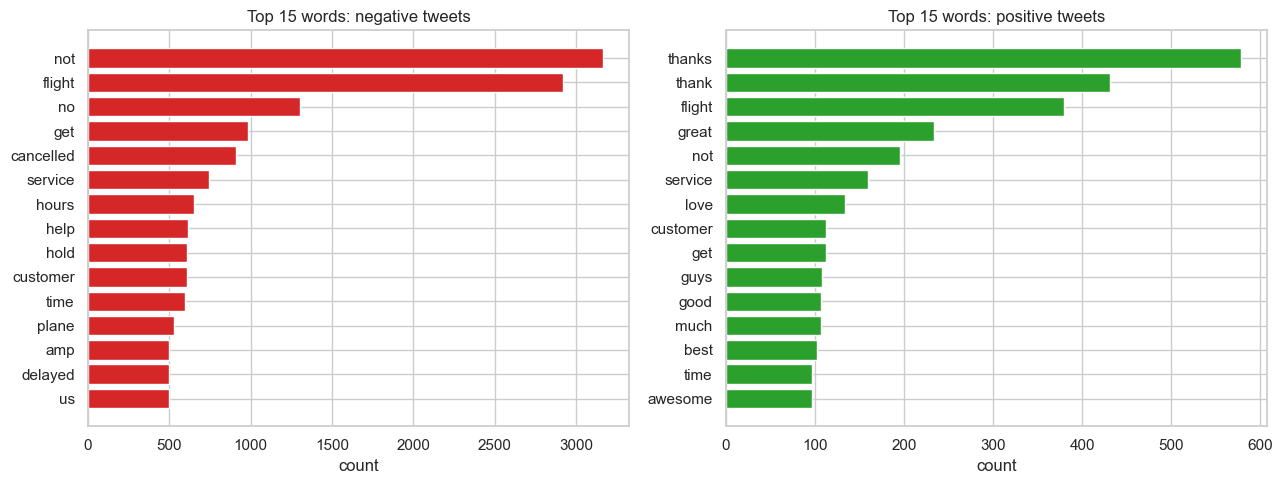

In [9]:
# 2.5 Vocabulary statistics
vocab_raw = set(w for t in df['text'] for w in t.lower().split())
vocab_clean = set(w for t in df['tokens'] for w in t)
print('vocabulary before cleaning:', len(vocab_raw), '| after cleaning + stop words:', len(vocab_clean))

freq = {s: Counter(w for t in df.loc[df['airline_sentiment'] == s, 'tokens'] for w in t) for s in order}
for s in order:
    print(f'\n20 most frequent tokens ({s}):', freq[s].most_common(20))

all_freq = Counter(w for t in df['tokens'] for w in t)
once = sum(1 for n in all_freq.values() if n == 1)
print(f'\nwords that appear only once: {once} ({once / len(all_freq):.1%} of the vocabulary)')

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, s, color in zip(ax, ['negative', 'positive'], ['tab:red', 'tab:green']):
    top = freq[s].most_common(15)[::-1]
    a.barh([w for w, n in top], [n for w, n in top], color=color)
    a.set(title=f'Top 15 words: {s} tweets', xlabel='count')
plt.tight_layout()
plt.savefig('screenshots/top_words.png', dpi=150)
plt.show()

# Task 3: Different NLP Approaches - Heuristic & API-based



In [10]:
# stratified 80/20 split BEFORE any vectoriser or Word2Vec model is fitted
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['airline_sentiment'])
y_train, y_test = train_df['airline_sentiment'], test_df['airline_sentiment']
print('train:', len(train_df), '| test:', len(test_df))
print(y_test.value_counts(normalize=True).round(3).to_dict())

# 3.2 Heuristic approach
print('lexicon sizes: positive =', len(POSITIVE_WORDS), '| negative =', len(NEGATIVE_WORDS))
hand_picked = pd.concat([test_df[y_test == s].head(n) for s, n in [('negative', 2), ('neutral', 1), ('positive', 2)]])
demo = pd.DataFrame({'tweet': hand_picked['text'].str[:90], 'true': hand_picked['airline_sentiment'],
                     'score': hand_picked['text'].apply(heuristic_score), 'predicted': hand_picked['text'].apply(heuristic_sentiment)})
print(demo.to_string(index=False))
print('negation check:', heuristic_score('the crew was not helpful'), 'vs', heuristic_score('the crew was helpful'))

train: 11541 | test: 2886
{'negative': 0.629, 'neutral': 0.212, 'positive': 0.159}
lexicon sizes: positive = 35 | negative = 38
                                                                                     tweet     true  score predicted
@SouthwestAir why doesn't your terminal B in LGA have pre-check? Makes me want to never fl negative      0   neutral
@united, b4 boarding this attendant took his shoe &amp;sock off at the desk and showed oth negative      0   neutral
                 @JetBlue alittle more money to book our flights... we're 1/2 way there :)  neutral      0   neutral
@united I forgot that Intl flights out of LAX don't go from Intl Terminal! Easiest re-chec positive      0   neutral
                         @SouthwestAir @love_dragonss oh my god LAUREN OH MY GOD OH MY GOD positive      0   neutral
negation check: -1 vs 1


In [11]:
# 3.3 API-based approach (NLTK VADER on the raw tweets)
test_df = test_df.assign(heuristic=test_df['text'].apply(heuristic_sentiment), vader=test_df['text'].apply(vader_sentiment))
print(test_df[['text', 'vader']].head(5).to_string(index=False))

                                                                                                                                          text    vader
                                      @SouthwestAir why doesn't your terminal B in LGA have pre-check? Makes me want to never fly your airline positive
@united, b4 boarding this attendant took his shoe &amp;sock off at the desk and showed other agents his foot. So gross. http://t.co/755VpYm4Mv negative
                                                                                                               @SouthwestAir link doesn't work  neutral
        @united it was UA flight 1001! Now I'm currently stuck in Portland because I missed my ride because of the 3 hour delay. #GetMartyHome negative
                                     @united I forgot that Intl flights out of LAX don't go from Intl Terminal! Easiest re-check in ever! woo! positive


===== Heuristic lexicon =====
              precision    recall  f1-score   support

    negative      0.920     0.413     0.570      1816
     neutral      0.308     0.788     0.443       612
    positive      0.608     0.675     0.640       458

    accuracy                          0.534      2886
   macro avg      0.612     0.625     0.551      2886
weighted avg      0.741     0.534     0.554      2886

===== VADER (API-style) =====
              precision    recall  f1-score   support

    negative      0.900     0.506     0.648      1816
     neutral      0.387     0.426     0.406       612
    positive      0.339     0.882     0.490       458

    accuracy                          0.549      2886
   macro avg      0.542     0.605     0.515      2886
weighted avg      0.702     0.549     0.571      2886



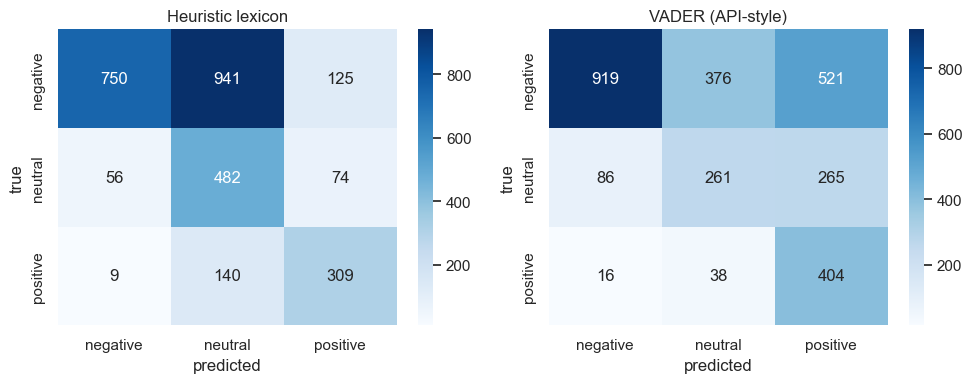

         Features     Classifier  Accuracy  Macro-F1  Precision (negative)  Recall (positive)  Training time (s)
Heuristic lexicon          Rules     0.534     0.551                  0.92              0.675                0.0
VADER (API-style) Pre-built tool     0.549     0.515                  0.90              0.882                0.0


In [12]:
# 3.4 Evaluate both on the same test set
results = []
def add_result(features, classifier, y_pred, train_time=0.0):
    macro = f1_score(y_test, y_pred, average='macro')
    results.append({'Features': features, 'Classifier': classifier, 'Accuracy': accuracy_score(y_test, y_pred), 'Macro-F1': macro,
                    'Precision (negative)': precision_score(y_test, y_pred, labels=['negative'], average=None)[0],
                    'Recall (positive)': recall_score(y_test, y_pred, labels=['positive'], average=None)[0],
                    'Training time (s)': round(train_time, 2)})
    return macro

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, col) in zip(ax, [('Heuristic lexicon', 'heuristic'), ('VADER (API-style)', 'vader')]):
    add_result(name, 'Rules' if col == 'heuristic' else 'Pre-built tool', test_df[col])
    print('=====', name, '=====')
    print(classification_report(y_test, test_df[col], digits=3))
    sns.heatmap(confusion_matrix(y_test, test_df[col], labels=order), annot=True, fmt='d', cmap='Blues', xticklabels=order, yticklabels=order, ax=a)
    a.set(title=name, xlabel='predicted', ylabel='true')
plt.tight_layout()
plt.savefig('screenshots/confusion_heuristic_vader.png', dpi=150)
plt.show()
print(pd.DataFrame(results).round(3).to_string(index=False))

In [13]:
# 3.5 Where do rules and ready-made tools fail?
def why(text, kind):
    t = text.lower()
    if re.search(r'delay|cancel|lost|wait|hold|late|stuck|bag|luggage|refund', t):
        return 'domain words such as delay / cancelled / bag are bad news in airline tweets but neutral for a general-purpose or short word list'
    if re.search(r"\b(not|no|never)\b|n't", t):
        return 'negation: the polarity of the next words is flipped, which is hard to handle with simple rules'
    if kind == 'heuristic' and heuristic_score(text) == 0:
        return 'none of the words are in my small lexicon, so the tweet defaults to neutral'
    return 'sarcasm, politeness words ("thanks", "please") or mixed feelings that do not match the label'

rows = []
for kind in ['heuristic', 'vader']:
    for _, r in test_df[test_df[kind] != test_df['airline_sentiment']].head(2).iterrows():
        rows.append({'approach': kind, 'tweet': r['text'][:110], 'true': r['airline_sentiment'], 'predicted': r[kind], 'cause': why(r['text'], kind)})
pd.DataFrame(rows)

,approach,tweet,true,predicted,cause
0,heuristic,@SouthwestAir why doesn't your terminal B in LGA have pre-check? Makes me want to never fly your airline,negative,neutral,"negation: the polarity of the next words is flipped, which is hard to handle with simple rules"
1,heuristic,"@united, b4 boarding this attendant took his shoe &amp;sock off at the desk and showed other agents his foot.",negative,neutral,"none of the words are in my small lexicon, so the tweet defaults to neutral"
2,vader,@SouthwestAir why doesn't your terminal B in LGA have pre-check? Makes me want to never fly your airline,negative,positive,"negation: the polarity of the next words is flipped, which is hard to handle with simple rules"
3,vader,@SouthwestAir link doesn't work,negative,neutral,"negation: the polarity of the next words is flipped, which is hard to handle with simple rules"


# Task 4: Feature Extraction - Bag-of-Words, TF-IDF & N-Grams


In [14]:
# 4.2 Bag-of-Words by hand and with sklearn
docs = ['the movie was good not bad', 'the movie was bad not good', 'the flight was delayed again', 'great crew and friendly staff']
word_lists = [d.split() for d in docs]
vocab = sorted(set(w for words in word_lists for w in words))
manual_bow = pd.DataFrame([[Counter(words)[w] for w in vocab] for words in word_lists], columns=vocab)

cv_demo = CountVectorizer()
sk_bow = pd.DataFrame(cv_demo.fit_transform(docs).toarray(), columns=cv_demo.get_feature_names_out())
print(manual_bow)
print('manual BoW == CountVectorizer:', manual_bow.equals(sk_bow))

   again  and  bad  crew  delayed  flight  friendly  good  great  movie  not  \
0      0    0    1     0        0       0         0     1      0      1    1   
1      0    0    1     0        0       0         0     1      0      1    1   
2      1    0    0     0        1       1         0     0      0      0    0   
3      0    1    0     1        0       0         1     0      1      0    0   

   staff  the  was  
0      0    1    1  
1      0    1    1  
2      0    1    1  
3      1    0    0  
manual BoW == CountVectorizer: True


In [15]:
# 4.3 TF-IDF by hand
N = len(docs)
tf = manual_bow.values
df_count = (tf > 0).sum(axis=0)
manual_tfidf = tf * (np.log(N / df_count) + 1)

sk_exact = TfidfVectorizer(smooth_idf=False, norm=None).fit_transform(docs).toarray()
print('manual TF-IDF matches TfidfVectorizer(smooth_idf=False, norm=None):', np.allclose(manual_tfidf, sk_exact))

sk_default = TfidfVectorizer().fit_transform(docs).toarray()
print('default TfidfVectorizer matches the manual formula:', np.allclose(manual_tfidf, sk_default))
print('row lengths  manual:', np.linalg.norm(manual_tfidf, axis=1).round(2), '| default:', np.linalg.norm(sk_default, axis=1).round(2))
print('idf of "was" (in 3 of 4 documents):', round(np.log(N / 3) + 1, 3), '| idf of "delayed" (in 1 document):', round(np.log(N / 1) + 1, 3))

manual TF-IDF matches TfidfVectorizer(smooth_idf=False, norm=None): True
default TfidfVectorizer matches the manual formula: False
row lengths  manual: [3.84 3.84 4.52 5.34] | default: [1. 1. 1. 1.]
idf of "was" (in 3 of 4 documents): 1.288 | idf of "delayed" (in 1 document): 2.386


In [16]:
# 4.4 BoW and TF-IDF on the airline tweets (fit on TRAIN only)
def describe(name, vec):
    X_train = vec.fit_transform(train_df['clean_text'])
    X_test = vec.transform(test_df['clean_text'])
    sparsity = 100 * (1 - X_train.nnz / (X_train.shape[0] * X_train.shape[1]))
    print(f'{name:28s} train {X_train.shape} test {X_test.shape} | vocabulary {len(vec.vocabulary_):6d} | non-zero {X_train.nnz:7d} | sparsity {sparsity:.2f}%')

describe('CountVectorizer', CountVectorizer())
describe('TfidfVectorizer', TfidfVectorizer())
describe('TfidfVectorizer min_df=2', TfidfVectorizer(min_df=2))
describe('TfidfVectorizer max_features=5000', TfidfVectorizer(max_features=5000))

CountVectorizer              train (11541, 9951) test (2886, 9951) | vocabulary   9951 | non-zero  168709 | sparsity 99.85%
TfidfVectorizer              train (11541, 9951) test (2886, 9951) | vocabulary   9951 | non-zero  168709 | sparsity 99.85%
TfidfVectorizer min_df=2     train (11541, 4950) test (2886, 4950) | vocabulary   4950 | non-zero  163708 | sparsity 99.71%
TfidfVectorizer max_features=5000 train (11541, 5000) test (2886, 5000) | vocabulary   5000 | non-zero  163758 | sparsity 99.72%


In [17]:
# 4.5 N-grams
for n in [(1, 1), (1, 2), (1, 3)]:
    print(f'ngram_range={n}: vocabulary size =', len(TfidfVectorizer(ngram_range=n).fit(train_df['clean_text']).vocabulary_))

tf12 = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X12 = tf12.fit_transform(train_df['clean_text'])
names = tf12.get_feature_names_out()
is_bigram = np.array([' ' in w for w in names])
for s in ['negative', 'positive']:
    mean_row = np.asarray(X12[(y_train == s).values].mean(axis=0)).ravel()
    top = [names[i] for i in mean_row.argsort()[::-1] if is_bigram[i]][:15]
    print(f'\n15 highest-weighted bigrams ({s}):', top)

neg_bigrams = [w for w in names[is_bigram] if w.split()[0] in NEGATIONS][:15]
print('\nbigrams that start with a negation word:', neg_bigrams)

ngram_range=(1, 1): vocabulary size = 9951
ngram_range=(1, 2): vocabulary size = 85645
ngram_range=(1, 3): vocabulary size = 213195

15 highest-weighted bigrams (negative): ['on hold', 'cancelled flightled', 'customer service', 'can not', 'on the', 'do not', 'my flight', 'to get', 'to be', 'hold for', 'trying to', 'this is', 'an hour', 'late flight', 'been on']

15 highest-weighted bigrams (positive): ['thank you', 'thanks for', 'for the', 'you for', 'you guys', 'so much', 'the best', 'customer service', 'for your', 'in the', 'to the', 'made it', 'thanks so', 'thanks to', 'you re']

bigrams that start with a negation word: ['never again', 'never arrived', 'never be', 'never been', 'never book', 'never do', 'never ever', 'never experienced', 'never fails', 'never fly', 'never flying', 'never get', 'never got', 'never had', 'never happened']


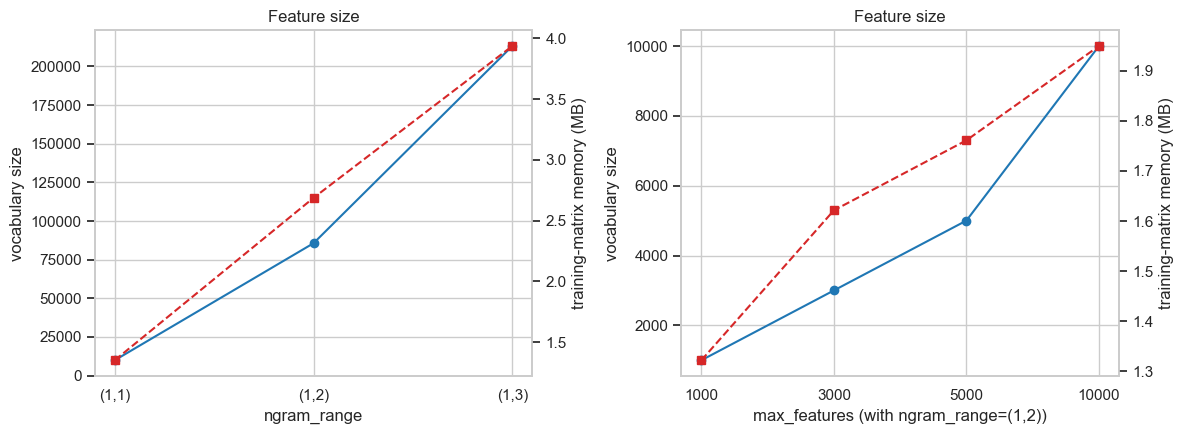

In [18]:
# 4.6 Feature-size experiment
def size_of(**kw):
    X = TfidfVectorizer(**kw).fit_transform(train_df['clean_text'])
    return X.shape[1], X.data.nbytes / 1e6

ngram_sizes = [size_of(ngram_range=(1, n)) for n in (1, 2, 3)]
max_features_list = [1000, 3000, 5000, 10000]
mf_sizes = [size_of(ngram_range=(1, 2), max_features=m) for m in max_features_list]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, labels, sizes, xlabel in [(ax[0], ['(1,1)', '(1,2)', '(1,3)'], ngram_sizes, 'ngram_range'),
                                 (ax[1], [str(m) for m in max_features_list], mf_sizes, 'max_features (with ngram_range=(1,2))')]:
    a.plot(labels, [s[0] for s in sizes], 'o-', color='tab:blue', label='vocabulary size')
    a.set(xlabel=xlabel, ylabel='vocabulary size', title='Feature size')
    b = a.twinx()
    b.plot(labels, [s[1] for s in sizes], 's--', color='tab:red', label='matrix memory (MB)')
    b.set_ylabel('training-matrix memory (MB)')
    b.grid(False)
plt.tight_layout()
plt.savefig('screenshots/feature_size_experiment.png', dpi=150)
plt.show()

# Task 5: Word Embeddings - Word2Vec (CBoW & Skip-gram)


In [19]:
# 5.3 Train both models on the TRAINING tweets
train_tokens = train_df['tokens'].tolist()
w2v = {}
for name, sg in [('CBoW', 0), ('Skip-gram', 1)]:
    t0 = time.time()
    w2v[name] = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=3, sg=sg, epochs=20, seed=42, workers=1)
    print(f"{name:10s} vocabulary: {len(w2v[name].wv)} | vector shape: {w2v[name].wv['flight'].shape} | training time: {time.time() - t0:.1f}s")

CBoW       vocabulary: 3563 | vector shape: (100,) | training time: 4.0s
Skip-gram  vocabulary: 3563 | vector shape: (100,) | training time: 9.7s


In [20]:
# 5.4 Explore the vectors
queries = ['delayed', 'flight', 'thanks', 'rude', 'luggage', 'great']
table = pd.DataFrame({'query': queries,
                      **{name: [', '.join(w for w, s in m.wv.most_similar(q, topn=5)) for q in queries] for name, m in w2v.items()}})
print(table.to_string(index=False))

for a, b in [('delayed', 'cancelled'), ('thanks', 'great'), ('flight', 'rude')]:
    print(f'cosine({a}, {b}):', {name: round(float(m.wv.similarity(a, b)), 3) for name, m in w2v.items()})

  query                                          CBoW                                           Skip-gram
delayed      missed, delay, layover, scheduled, three       connections, grounded, departed, routing, cdg
 flight flt, flights, departure, notified, connecting                 ind, discovered, nite, causing, lit
 thanks      thank, speedy, prompt, everything, quick           thank, responses, prompt, thx, everything
   rude  staff, helpful, employees, unhelpful, agents unhelpful, unprofessional, attitude, karen, equally
luggage               bags, bag, baggage, found, item                  carousel, bag, tag, baggage, lands
  great   awesome, job, fantastic, excellent, amazing     wonderful, awesome, outstanding, fantastic, job
cosine(delayed, cancelled): {'CBoW': 0.48, 'Skip-gram': 0.399}
cosine(thanks, great): {'CBoW': 0.567, 'Skip-gram': 0.323}
cosine(flight, rude): {'CBoW': 0.152, 'Skip-gram': 0.314}


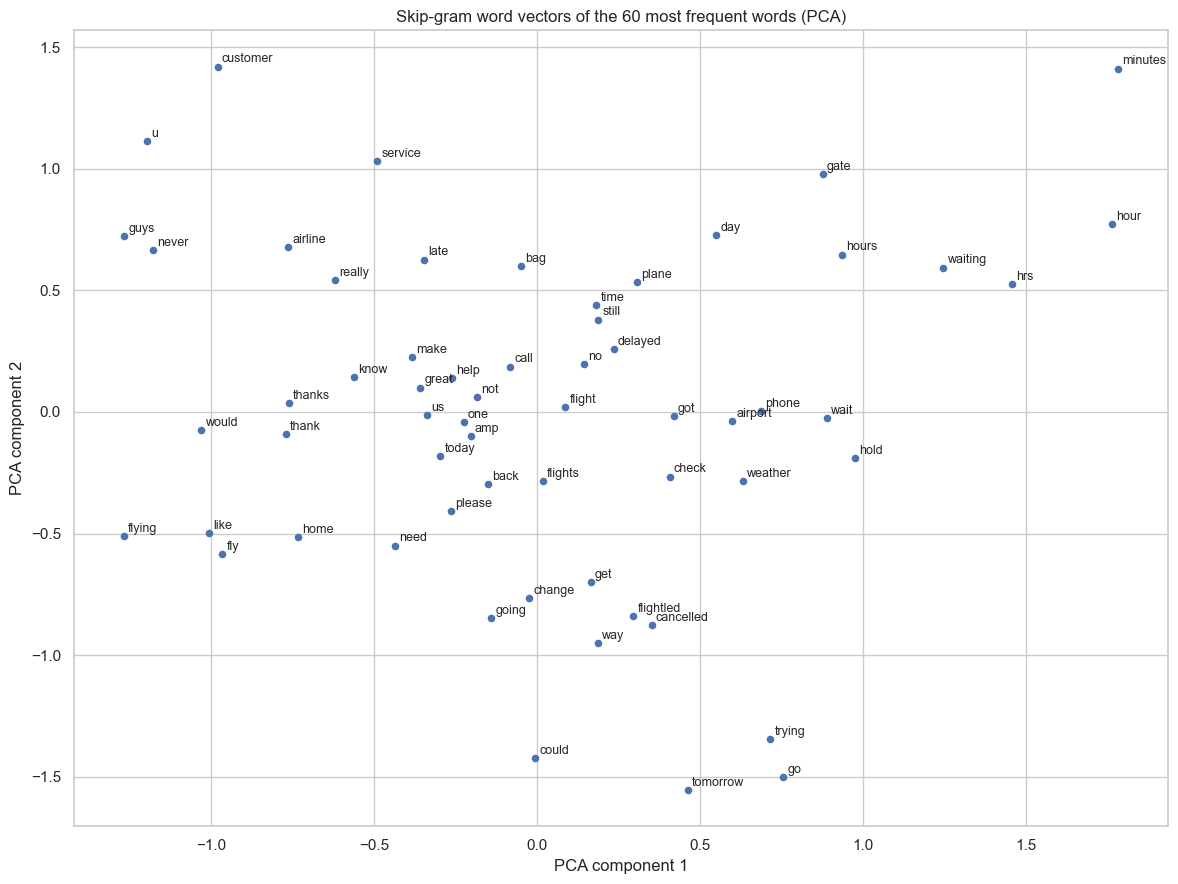

In [21]:
# 5.5 Visualise the 60 most frequent words (Skip-gram vectors)
words = w2v['Skip-gram'].wv.index_to_key[:60]
points = PCA(n_components=2, random_state=42).fit_transform(w2v['Skip-gram'].wv[words])

plt.figure(figsize=(12, 9))
plt.scatter(points[:, 0], points[:, 1], s=20)
for w, (x, y) in zip(words, points):
    plt.annotate(w, (x, y), xytext=(3, 3), textcoords='offset points', fontsize=9)
plt.title('Skip-gram word vectors of the 60 most frequent words (PCA)')
plt.xlabel('PCA component 1')
plt.ylabel('PCA component 2')
plt.tight_layout()
plt.savefig('screenshots/word2vec_pca.png', dpi=150)
plt.show()

In [22]:
# 5.6 From word vectors to document vectors
def doc_vector(tokens, model):
    vectors = [model.wv[w] for w in tokens if w in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)

best_w2v = w2v['Skip-gram']      # chosen after reading the table in 5.4: Skip-gram copes better with rare words on a small corpus
X_train_w2v = np.array([doc_vector(t, best_w2v) for t in train_df['tokens']])
X_test_w2v = np.array([doc_vector(t, best_w2v) for t in test_df['tokens']])
print('X_train_w2v:', X_train_w2v.shape, '| X_test_w2v:', X_test_w2v.shape)

X_train_w2v: (11541, 100) | X_test_w2v: (2886, 100)


# Task 6: Text Classification Pipeline & Approach Comparison



accuracy: 0.7983 | macro-F1: 0.7518
              precision    recall  f1-score   support

    negative      0.891     0.849     0.870      1816
     neutral      0.609     0.681     0.643       612
    positive      0.732     0.753     0.743       458

    accuracy                          0.798      2886
   macro avg      0.744     0.761     0.752      2886
weighted avg      0.806     0.798     0.801      2886



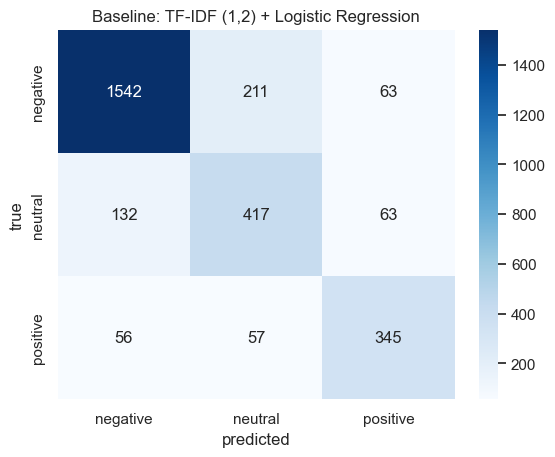

In [23]:
# 6.2 Baseline pipeline
baseline = Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
                     ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))])
t0 = time.time()
baseline.fit(train_df['clean_text'], y_train)
train_time = time.time() - t0

pred = baseline.predict(test_df['clean_text'])
add_result('TF-IDF (1,2)', 'Logistic Regression', pred, train_time)
print('accuracy:', round(accuracy_score(y_test, pred), 4), '| macro-F1:', round(f1_score(y_test, pred, average='macro'), 4))
print(classification_report(y_test, pred, digits=3))
sns.heatmap(confusion_matrix(y_test, pred, labels=order), annot=True, fmt='d', cmap='Blues', xticklabels=order, yticklabels=order)
plt.title('Baseline: TF-IDF (1,2) + Logistic Regression')
plt.xlabel('predicted')
plt.ylabel('true')
plt.savefig('screenshots/confusion_baseline.png', dpi=150, bbox_inches='tight')
plt.show()

In [24]:
# 6.3 Compare feature approaches on the same split (nothing is tuned on the test set)
text_pipelines = {('TF-IDF (1,2)', 'Logistic Regression'): baseline,
                  ('BoW', 'Multinomial NB'): Pipeline([('bow', CountVectorizer(min_df=2)), ('clf', MultinomialNB())]),
                  ('BoW', 'Logistic Regression'): Pipeline([('bow', CountVectorizer(min_df=2)), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))]),
                  ('TF-IDF (1,1)', 'Logistic Regression'): Pipeline([('tfidf', TfidfVectorizer(min_df=2)), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))])}
scores = {('TF-IDF (1,2)', 'Logistic Regression'): results[-1]['Macro-F1']}
for key, pipe in text_pipelines.items():
    if key in scores:
        continue
    t0 = time.time()
    pipe.fit(train_df['clean_text'], y_train)
    scores[key] = add_result(*key, pipe.predict(test_df['clean_text']), time.time() - t0)

t0 = time.time()
lr_w2v = LogisticRegression(max_iter=1000, class_weight='balanced').fit(X_train_w2v, y_train)
add_result('Word2Vec average', 'Logistic Regression', lr_w2v.predict(X_test_w2v), time.time() - t0)

results_df = pd.DataFrame(results).round(3)
results_df['Best'] = np.where(results_df['Macro-F1'] == results_df['Macro-F1'].max(), '<- best macro-F1', '')
print(results_df.to_string(index=False))

         Features          Classifier  Accuracy  Macro-F1  Precision (negative)  Recall (positive)  Training time (s)             Best
Heuristic lexicon               Rules     0.534     0.551                 0.920              0.675               0.00                 
VADER (API-style)      Pre-built tool     0.549     0.515                 0.900              0.882               0.00                 
     TF-IDF (1,2) Logistic Regression     0.798     0.752                 0.891              0.753               1.61 <- best macro-F1
              BoW      Multinomial NB     0.779     0.701                 0.816              0.668               0.36                 
              BoW Logistic Regression     0.763     0.720                 0.899              0.764               1.78                 
     TF-IDF (1,1) Logistic Regression     0.769     0.729                 0.893              0.771               1.04                 
 Word2Vec average Logistic Regression     0.716     0.6

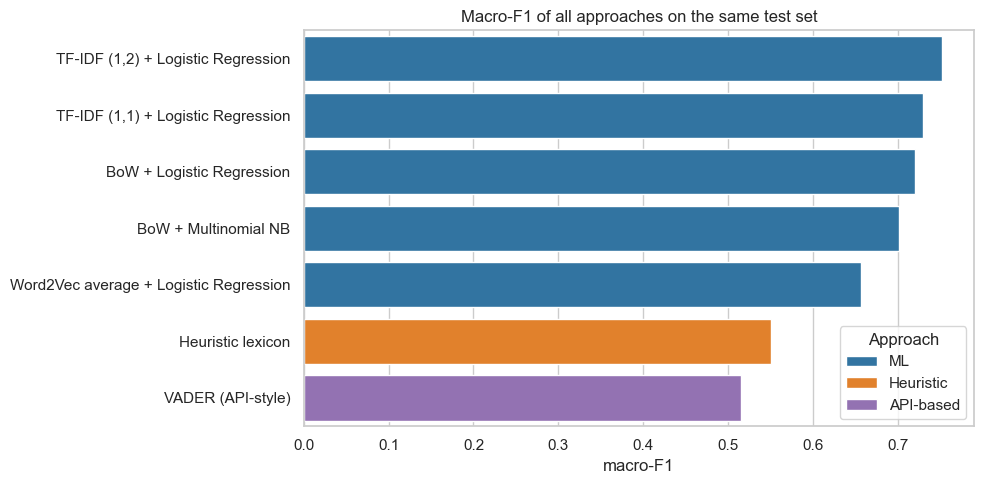

Ranking: TF-IDF (1,2) + Logistic Regression (0.752) > TF-IDF (1,1) + Logistic Regression (0.729) > BoW + Logistic Regression (0.720) > BoW + Multinomial NB (0.701) > Word2Vec average + Logistic Regression (0.657) > Heuristic lexicon (0.551) > VADER (API-style) (0.515)
I would deploy: ('TF-IDF (1,2)', 'Logistic Regression') - the highest macro-F1 among the pipelines that take text directly (one object, one predict call).


In [25]:
# 6.4 All three NLP approaches in one chart
families = {'Heuristic lexicon': 'Heuristic', 'VADER (API-style)': 'API-based'}
results_df['Approach'] = [families.get(f, 'ML') for f in results_df['Features']]
results_df['Name'] = np.where(results_df['Approach'] == 'ML', results_df['Features'] + ' + ' + results_df['Classifier'], results_df['Features'])
ranked = results_df.sort_values('Macro-F1', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=ranked, y='Name', x='Macro-F1', hue='Approach', dodge=False,
            palette={'Heuristic': 'tab:orange', 'API-based': 'tab:purple', 'ML': 'tab:blue'})
plt.title('Macro-F1 of all approaches on the same test set')
plt.xlabel('macro-F1')
plt.ylabel('')
plt.tight_layout()
plt.savefig('screenshots/comparison_all_approaches.png', dpi=150)
plt.show()

print('Ranking:', ' > '.join(f'{n} ({v:.3f})' for n, v in zip(ranked['Name'], ranked['Macro-F1'])))
best_key = max(scores, key=scores.get)
print('I would deploy:', best_key, '- the highest macro-F1 among the pipelines that take text directly (one object, one predict call).')

In [26]:
# 6.5 Cross-validation of the best pipeline (training data only)
best_pipe = text_pipelines[best_key]
cv_scores = cross_val_score(best_pipe, train_df['clean_text'], y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='f1_macro')
print('best pipeline:', best_key)
print(f'5-fold macro-F1: mean = {cv_scores.mean():.3f}, std = {cv_scores.std():.3f} | test macro-F1 = {scores[best_key]:.3f}')

best pipeline: ('TF-IDF (1,2)', 'Logistic Regression')
5-fold macro-F1: mean = 0.737, std = 0.006 | test macro-F1 = 0.752


In [27]:
# 6.6 Error analysis
proba = best_pipe.predict_proba(test_df['clean_text']).max(axis=1)
errors = test_df.assign(predicted=best_pipe.predict(test_df['clean_text']), probability=proba.round(2))
errors = errors[errors['predicted'] != errors['airline_sentiment']]

def pattern(r):
    t = r['text'].lower()
    if len(r['clean_text'].split()) <= 5:
        return 'very short tweet'
    if re.search(r"\b(not|no|never)\b|n't", t):
        return 'negation'
    if re.search(r'\b(but|however|although)\b', t):
        return 'mixed opinion'
    return f"{r['airline_sentiment']} confused with {r['predicted']}"

errors['pattern'] = errors.apply(pattern, axis=1)
print('misclassified:', len(errors), 'of', len(test_df))
print(errors['pattern'].value_counts().head(6))
errors.sample(8, random_state=42)[['text', 'airline_sentiment', 'predicted', 'probability', 'pattern']].rename(columns={'airline_sentiment': 'true'})

misclassified: 582 of 2886
pattern
negative confused with neutral     142
negation                           115
neutral confused with negative      78
very short tweet                    61
negative confused with positive     46
positive confused with neutral      41
Name: count, dtype: int64


,text,true,predicted,probability,pattern
3136,@united what is your plan to reduce delays?,neutral,negative,0.48,neutral confused with negative
11879,@AmericanAir Trying desperately to get my boyfriend booked on the same US Airways flight as myself for the same price. Can you help?,negative,neutral,0.54,negative confused with neutral
8833,@JetBlue I applied for a job at PDW where could I go for follow up. I'd really love the job #ilovejetblue,neutral,positive,0.79,neutral confused with positive
13576,@AmericanAir by far the best example of the worst company @Cowboycerrone,negative,positive,0.52,negative confused with positive
5691,@SouthwestAir #DestinationDragons iD is my favorite band and i met my 2bestfriends thanks to them! it would be life changing to see them!,neutral,positive,0.62,neutral confused with positive
5613,@SouthwestAir did you Cancelled Flight ALL flights into BNA today??? #needtogethome,negative,neutral,0.47,negative confused with neutral
9397,"@usairways Row 16, flight 634 today if you're looking for specifics! I can run to Home Depot for the WD40 you if you need.",negative,neutral,0.61,negative confused with neutral
6083,"@SouthwestAir So I am flying Chicago-LAX-PHX just to go spotting at LAX and PHX airports, then I am flying back to Chicago :)",neutral,positive,0.43,neutral confused with positive


In [28]:
# 6.7 Save the final pipeline (cleaning is done separately by clean_text)
joblib.dump(best_pipe, 'model/sentiment_model.joblib')
print('scikit-learn version used:', sklearn.__version__)

model = joblib.load('model/sentiment_model.joblib')
for s in ['Thank you so much, the crew was wonderful!', 'Three hours late and nobody tells us anything. Never again.', 'What time does the gate open?']:
    print(f"{model.predict([clean_text(s)])[0]:9s} {model.predict_proba([clean_text(s)]).max():.2f}  {s}")

scikit-learn version used: 1.5.2
positive  0.98  Thank you so much, the crew was wonderful!
negative  0.95  Three hours late and nobody tells us anything. Never again.
neutral   0.72  What time does the gate open?


# Task 7: POS Tagging



In [29]:
# 7.3 Tag sentences (cleaned, but NOT stop-word filtered)
tweets = test_df['clean_text'].head(5).tolist()
ambiguity = ['please book my ticket now', 'i read a good book on the flight']
rows = [(i, w, t) for i, s in enumerate(tweets + ambiguity, 1) for w, t in nltk.pos_tag(nltk.word_tokenize(s))]
tags = pd.DataFrame(rows, columns=['sentence', 'word', 'tag'])
print(tags.groupby('sentence').apply(lambda g: ' '.join(f'{w}/{t}' for w, t in zip(g['word'], g['tag']))).to_string())

sentence
1      why/WRB does/VBZ not/RB your/PRP$ terminal/NN b/NN in/IN lga/NN have/VBP pre/VBN check/NN makes/VBZ me/PRP want/VB to/TO never/RB fly/VB your/PRP$ airline/NN
2    b/NN boarding/VBG this/DT attendant/JJ took/VBD his/PRP$ shoe/NN amp/IN sock/NN off/NN at/IN the/DT desk/NN and/CC showed/VBD other/JJ agents/NNS his/PRP$ f...
3                                                                                                                                    link/NN does/VBZ not/RB work/VB
4    it/PRP was/VBD ua/JJ flight/NN now/RB i/VBZ m/VBP currently/RB stuck/VBN in/IN portland/NN because/IN i/NN missed/VBD my/PRP$ ride/NN because/IN of/IN the/D...
5    i/NN forgot/VBD that/IN intl/JJ flights/NNS out/IN of/IN lax/NNS do/VBP not/RB go/VB from/IN intl/JJ terminal/JJ easiest/JJS re/NN check/NN in/IN ever/RB wo...
6                                                                                                                         please/NN book/NN my/PRP$ ticket/NN now/RB
7

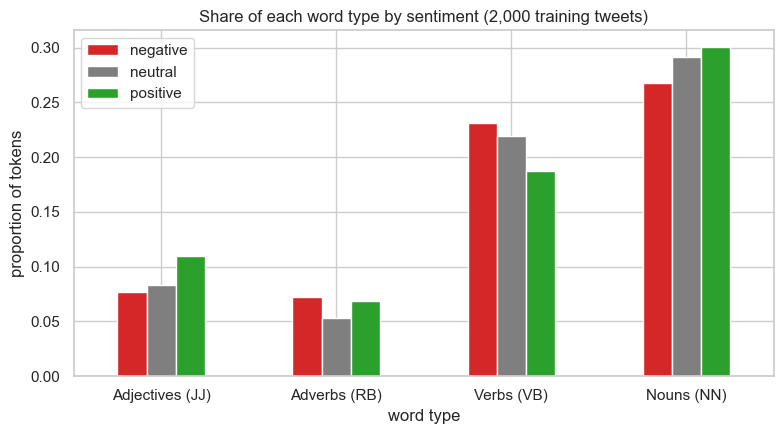

                 negative  neutral  positive
Adjectives (JJ)     0.077    0.083     0.110
Adverbs (RB)        0.072    0.053     0.069
Verbs (VB)          0.231    0.219     0.187
Nouns (NN)          0.268    0.291     0.301

10 most frequent adjectives (negative): [('i', 112), ('late', 55), ('worst', 41), ('more', 34), ('last', 32), ('flightled', 31), ('united', 28), ('u', 28), ('due', 26), ('other', 25)]

10 most frequent adjectives (positive): [('great', 29), ('best', 15), ('much', 13), ('i', 12), ('awesome', 11), ('good', 10), ('nice', 8), ('helpful', 7), ('excellent', 7), ('last', 7)]


In [30]:
# 7.4 POS distribution by sentiment (2,000 training tweets)
sample = train_df.sample(2000, random_state=42)
groups = {'Adjectives (JJ)': 'JJ', 'Adverbs (RB)': 'RB', 'Verbs (VB)': 'VB', 'Nouns (NN)': 'NN'}
tagged = {s: [p for t in sample.loc[sample['airline_sentiment'] == s, 'clean_text'] for p in nltk.pos_tag(nltk.word_tokenize(t))] for s in order}

dist = pd.DataFrame({s: {g: sum(t.startswith(p) for w, t in tagged[s]) / len(tagged[s]) for g, p in groups.items()} for s in order})
dist.plot(kind='bar', figsize=(8, 4.5), color=['tab:red', 'tab:gray', 'tab:green'])
plt.title('Share of each word type by sentiment (2,000 training tweets)')
plt.xlabel('word type')
plt.ylabel('proportion of tokens')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('screenshots/pos_distribution.png', dpi=150)
plt.show()
print(dist.round(3))
for s in ['negative', 'positive']:
    print(f'\n10 most frequent adjectives ({s}):', Counter(w for w, t in tagged[s] if t.startswith('JJ')).most_common(10))

In [31]:
# 7.5 POS-filtered features: keep adjectives, adverbs, verbs and negation words
def pos_filter(text):
    return ' '.join(w for w, t in nltk.pos_tag(nltk.word_tokenize(text)) if t.startswith(('JJ', 'RB', 'VB')) or w in NEGATIONS)

pos_train = train_df['clean_text'].apply(pos_filter)
pos_test = test_df['clean_text'].apply(pos_filter)
pos_pipe = Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
                     ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))])
t0 = time.time()
pos_pipe.fit(pos_train, y_train)
pos_f1 = add_result('TF-IDF (1,2), POS-filtered', 'Logistic Regression', pos_pipe.predict(pos_test), time.time() - t0)

full_f1 = scores[('TF-IDF (1,2)', 'Logistic Regression')]
change = 'helped' if pos_f1 - full_f1 > 0.005 else 'hurt' if full_f1 - pos_f1 > 0.005 else 'made no real difference'
print(f'macro-F1 full text = {full_f1:.3f} | POS-filtered = {pos_f1:.3f} -> POS filtering {change}.')

macro-F1 full text = 0.752 | POS-filtered = 0.638 -> POS filtering hurt.


# Task 8: Build the NLP Project and Deploy on Streamlit


In [32]:
# 8.4 Robustness test of the shared code with the 6 inputs used for the app test
tests = ['', '😡😡😡', 'WORST AIRLINE EVER!!! MY BAG IS LOST AGAIN', 'The flight was not good at all', 'http://t.co/abc123', 'Thanks for the smooth flight, great crew!']
for s in tests:
    cleaned = clean_text(s)
    print(f'{s[:45]!r:50} cleaned={cleaned!r:40} heuristic={heuristic_sentiment(s):9s} VADER={vader_sentiment(s):9s} ML={model.predict([cleaned])[0] if cleaned else "(empty -> warning in app)"}')

''                                                 cleaned=''                                       heuristic=neutral   VADER=neutral   ML=(empty -> warning in app)
'😡😡😡'                                              cleaned=''                                       heuristic=neutral   VADER=neutral   ML=(empty -> warning in app)
'WORST AIRLINE EVER!!! MY BAG IS LOST AGAIN'       cleaned='worst airline ever my bag is lost again' heuristic=negative  VADER=negative  ML=negative
'The flight was not good at all'                   cleaned='the flight was not good at all'         heuristic=negative  VADER=negative  ML=negative
'http://t.co/abc123'                               cleaned=''                                       heuristic=neutral   VADER=neutral   ML=(empty -> warning in app)
'Thanks for the smooth flight, great crew!'        cleaned='thanks for the smooth flight great crew' heuristic=positive  VADER=positive  ML=positive


In [33]:
# requirements.txt for the app: only the libraries it needs, with the versions used here (same scikit-learn as the saved model)
import importlib.metadata as imd
libs = ['streamlit', 'scikit-learn', 'nltk', 'pandas', 'numpy', 'joblib']
with open('requirements.txt', 'w') as f:
    f.write('\n'.join(f'{p}=={imd.version(p)}' for p in libs) + '\n')
print(open('requirements.txt').read())

streamlit==1.40.1
scikit-learn==1.5.2
nltk==3.9.1
pandas==2.2.3
numpy==2.0.0
joblib==1.4.2



In [34]:
macro = {(r['Features'], r['Classifier']): r['Macro-F1'] for r in results}
best_ml = max(v for (f, c), v in macro.items() if c == 'Logistic Regression' or 'NB' in c)
stages = {'moving from rules / ready-made tool to a trained model': best_ml - max(macro[('Heuristic lexicon', 'Rules')], macro[('VADER (API-style)', 'Pre-built tool')]),
          'BoW -> TF-IDF features': macro[('TF-IDF (1,1)', 'Logistic Regression')] - macro[('BoW', 'Logistic Regression')],
          'unigrams -> unigrams + bigrams': macro[('TF-IDF (1,2)', 'Logistic Regression')] - macro[('TF-IDF (1,1)', 'Logistic Regression')]}
for k, v in stages.items():
    print(f'{v:+.3f} macro-F1: {k}')
print('Biggest effect:', max(stages, key=stages.get))

+0.201 macro-F1: moving from rules / ready-made tool to a trained model
+0.009 macro-F1: BoW -> TF-IDF features
+0.023 macro-F1: unigrams -> unigrams + bigrams
Biggest effect: moving from rules / ready-made tool to a trained model
